<a href="https://colab.research.google.com/github/Willmch161/AppGUIJAVA/blob/main/Task_practical_work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install numpy imageio matplotlib

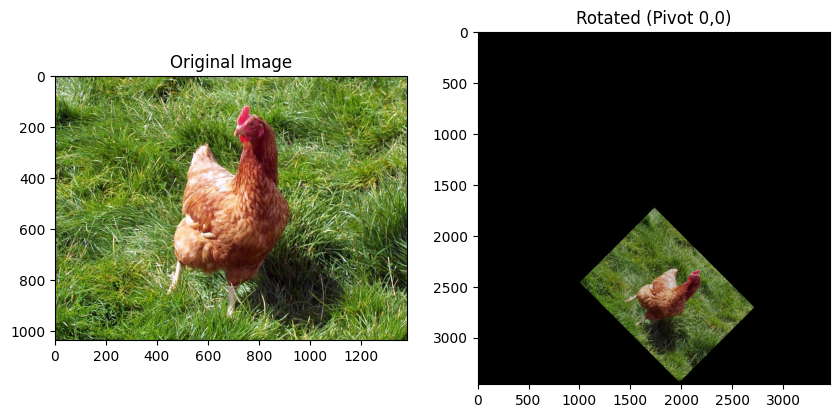

In [7]:
import imageio.v2 as img
import numpy as np
import matplotlib.pyplot as plt

def rotateImagePivotZero(image, degree):
    radian_deg = np.radians(degree)
    cos_deg = np.cos(radian_deg)
    sin_deg = np.sin(radian_deg)

    height, width = image.shape[:2]
    # Calculate the maximum possible dimension to prevent cropping
    max_dim = int(np.sqrt(height**2 + width**2))

    # Create a larger output canvas with an offset to handle negative coordinates
    outputImage = np.zeros((max_dim * 2, max_dim * 2, 3), dtype=image.dtype)
    offset = max_dim

    for y in range(height):
        for x in range(width):
            # Calculate new coordinates pivoting from (0,0)
            newX = int(cos_deg * x - sin_deg * y)
            newY = int(sin_deg * x + cos_deg * y)

            # Apply offset and map to the output image
            if 0 <= newX + offset < max_dim * 2 and 0 <= newY + offset < max_dim * 2:
                outputImage[newY + offset, newX + offset] = image[y, x]

    return outputImage

# Load and process the image
image = img.imread('sample_data/image.jpg') # Update with your image path
rotated_image = rotateImagePivotZero(image, 45) # Rotate by 45 degrees

# Display the results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Rotated (Pivot 0,0)")
plt.imshow(rotated_image)

plt.show()

/tmp/ipykernel_8557/3177003495.py:6: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread(path)


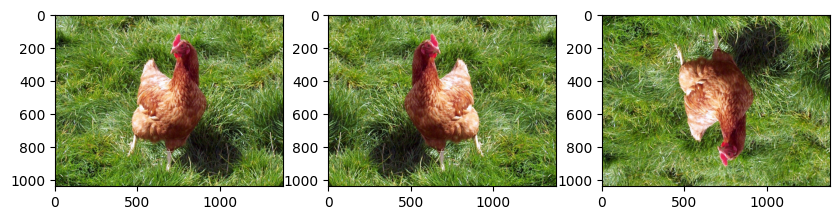

In [12]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

path = 'sample_data/image.jpg'
image = img.imread(path)

height, width = image.shape[:2]
horizontal = np.zeros_like(image)
vertical = np.zeros_like(image)

for y in range(height):
    for x in range(width):
        horizontal[y, x] = image[y, width - 1 - x]

for y in range(height):
    for x in range(width):
        vertical[y, x] = image[height - 1 - y, x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)

plt.subplot(1, 3, 2)
plt.imshow(horizontal)

plt.subplot(1, 3, 3)
plt.imshow(vertical)

plt.show()

/tmp/ipykernel_8557/1033586962.py:24: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('sample_data/image.jpg')


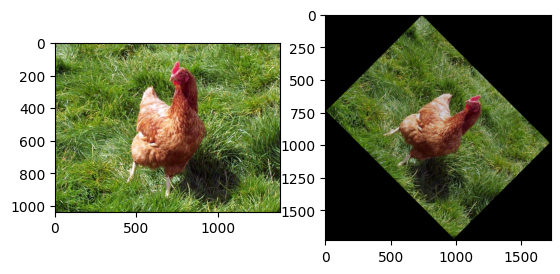

In [13]:
import imageio as img
import numpy as np
import matplotlib.pyplot as plt

def rotateImage(image, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    max_dim = int(np.sqrt(height**2 + width**2))
    outputImage = np.zeros((max_dim, max_dim, 3), dtype=image.dtype)

    centerY, centerX = max_dim//2, max_dim//2

    for y in range(-height//2, height//2):
        for x in range(-width//2, width//2):
            newX = int(cos_deg * x - sin_deg * y) + centerX
            newY = int(sin_deg * x + cos_deg * y) + centerY

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[y + height//2, x + width//2]
    return outputImage

image = img.imread('sample_data/image.jpg')

rotated_image = rotateImage(image, 45)

plt.subplot(1, 2, 1)
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.imshow(rotated_image)

plt.show()

/tmp/ipykernel_8557/2051541335.py:25: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('sample_data/image.jpg')


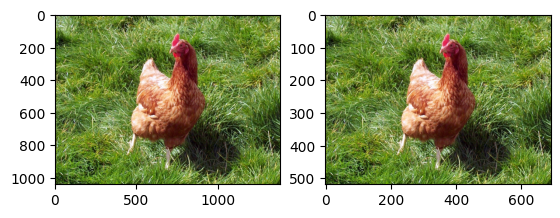

In [14]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

def zoomPlus(image, factor):
    height, width = image.shape[:2]
    new_height = int(height / factor)
    new_width = int(width / factor)
    imgZoom = np.zeros((new_height, new_width, 3), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):

            ori_y = int(y * factor)
            ori_x = int(x * factor)

            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom


image = img.imread('sample_data/image.jpg')
skala = 2.0

imgZoom = zoomPlus(image, skala)
img.imwrite("z.jpg", imgZoom)
plt.subplot(1, 2, 1)
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.imshow(imgZoom)
plt.show()

/tmp/ipykernel_8557/3634240495.py:5: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('sample_data/image.jpg')


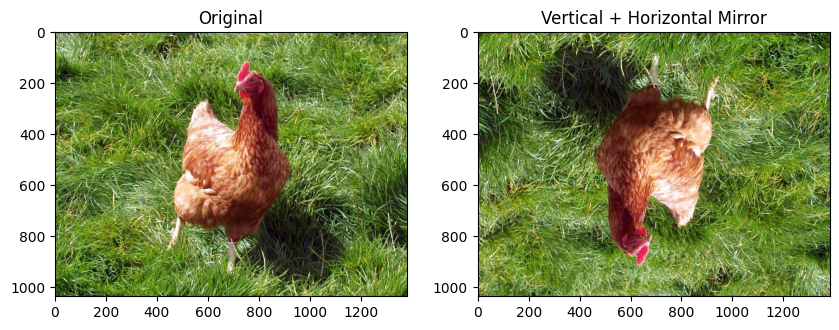

In [15]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

image = img.imread('sample_data/image.jpg')
height, width = image.shape[:2]

both = np.zeros_like(image)

for y in range(height):
    for x in range(width):
        both[y, x] = image[height - 1 - y, width - 1 - x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Original")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Vertical + Horizontal Mirror")
plt.imshow(both)

plt.show()

/tmp/ipykernel_8557/3117219820.py:22: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('sample_data/image.jpg')


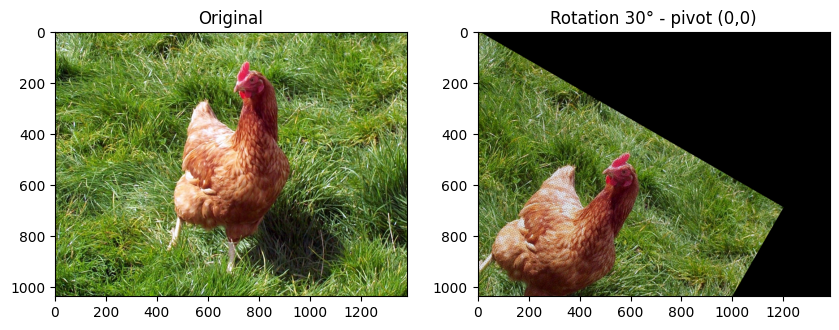

In [16]:
import imageio as img
import numpy as np
import matplotlib.pyplot as plt

def rotateCorner(image, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    # Same size canvas as the original, pivot is (0,0)
    outputImage = np.zeros_like(image)

    for y in range(height):
        for x in range(width):
            newX = int(cos_deg * x - sin_deg * y)
            newY = int(sin_deg * x + cos_deg * y)

            if 0 <= newX < width and 0 <= newY < height:
                outputImage[newY, newX] = image[y, x]
    return outputImage

image = img.imread('sample_data/image.jpg')

rotated_image = rotateCorner(image, 30)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Original")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Rotation 30° - pivot (0,0)")
plt.imshow(rotated_image)

plt.show()